# Market regimes for faster research decisions

## Summary

Recognize a market change, decide what needs recalibration, and inspect what happens next. This notebook combines immediate alerts, deliberately delayed confirmation, and full-history interpretation across eight asset classes. The numerical summary below is generated from the executed results.

## Context and methods

The maintained HMM reads four smoothed asset-group risk levels and a stock–bond dependence feature. The raw-return HMM is retained as a benchmark. This feature amendment follows the first replay and remains exploratory. The practical action is a risk-model review: an alert resets the second-moment estimate to the latest 20 observations and uses faster updating for a month. We compare it with continuous slow and fast EWMA. A separate HMM state forecast answers a different question.

### Key assumptions

All observations are revised adjusted-close proxies. The study is retrospective. A forecast at close t is scored on t+1 through t+5; a delayed label records both the date it describes and the date it becomes available. Full-history labels never enter decisions. The loss measures risk calibration, not strategy returns.

[Methods](docs/01-methods.md) · [Frozen protocol](research/PROTOCOL.md) · [Plotting calculations](research/practical_plots.py).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from research.run_study import main
from research.practical_config import ROOT, RESULTS, FIGURES, ASSETS
from research.practical_data import load_data
main()
prices, returns = load_data()

Reused HMM checkpoint: primary


Reused HMM checkpoint: raw_return


Reused HMM checkpoint: two_states


Reused HMM checkpoint: seed_41


            contrast  estimate   lower95  upper95    n  block  draws         endpoint
           Fast EWMA -0.002190 -0.038031 0.024856 4600     63   2000 Eight-asset mean
           HMM reset -0.000457 -0.024880 0.016732 4600     63   2000 Eight-asset mean
  HMM state forecast  0.188945  0.060678 0.412710 4600     63   2000 Eight-asset mean
    Observable reset -0.002344 -0.009586 0.002096 4600     63   2000 Eight-asset mean
Raw-return HMM reset -0.013662 -0.044947 0.007623 4600     63   2000 Eight-asset mean


Completed practical regime study: {'hmm_refits': 220, 'representation': 'EWMA risk levels and equity-bond dependence', 'calibration_warmup': 567, 'label_switch_fraction': np.float64(0.0317115551694179), 'raw_return_failed_refits': 0, 'failed_primary_refits': 0, 'first_decision': '2008-06-02', 'last_decision': '2026-09-21', 'first_scored_outcome': '2008-06-03', 'last_scored_outcome': '2026-09-21', 'sessions_scored': 4600}


In [2]:
comparison = pd.read_csv(RESULTS / "calibration_comparison.csv")
primary = comparison.query('endpoint == "Eight-asset mean" and block == 63')
display(primary[["contrast", "estimate", "lower95", "upper95", "n"]].round(4))

,contrast,estimate,lower95,upper95,n
0,Fast EWMA,-0.0022,-0.0380,0.0249,4600
1,HMM reset,-0.0005,-0.0249,0.0167,4600
2,HMM state forecast,0.1889,0.0607,0.4127,4600
3,Observable reset,-0.0023,-0.0096,0.0021,4600
4,Raw-return HMM reset,-0.0137,-0.0449,0.0076,4600


Negative loss differences favor the alternative. Read each estimate with its interval. The HMM-triggered reset and the direct state forecast answer different questions. The raw-return reset provides a matched-period representation control; a smoother state map is not automatically a better risk model.

## Data

Eight surviving fund proxies, March 2006–21 September 2026. Names describe economic exposures; currency, duration, credit and commodity-roll effects remain inside their returns. The common cutoff avoids a missing provider session rather than filling a price.

In [3]:
manifest = json.loads((ROOT / "research/data/practical_manifest.json").read_text())
display(pd.DataFrame(manifest["snapshots"])[["name", "ticker", "first_date", "last_date", "rows"]])
display(pd.Series(json.loads((RESULTS / "data_audit.json").read_text()))[["price_rows", "assets", "missing", "duplicates", "fills"]])

,name,ticker,first_date,last_date,rows
0,US equities,SPY,2006-03-01,2026-09-21,5172
1,Developed ex-US equities,EFA,2006-03-01,2026-09-21,5172
2,Emerging-market equities,EEM,2006-03-01,2026-09-21,5172
3,Intermediate Treasuries,IEF,2006-03-01,2026-09-21,5172
4,Long Treasuries,TLT,2006-03-01,2026-09-21,5172
5,Investment-grade credit,LQD,2006-03-01,2026-09-21,5172
6,Gold,GLD,2006-03-01,2026-09-21,5172
7,Broad commodities,DBC,2006-03-01,2026-09-21,5172


price_rows    5172
assets           8
missing          0
duplicates       0
fills            0
dtype: object

## Results

### 1. Start with the economic picture

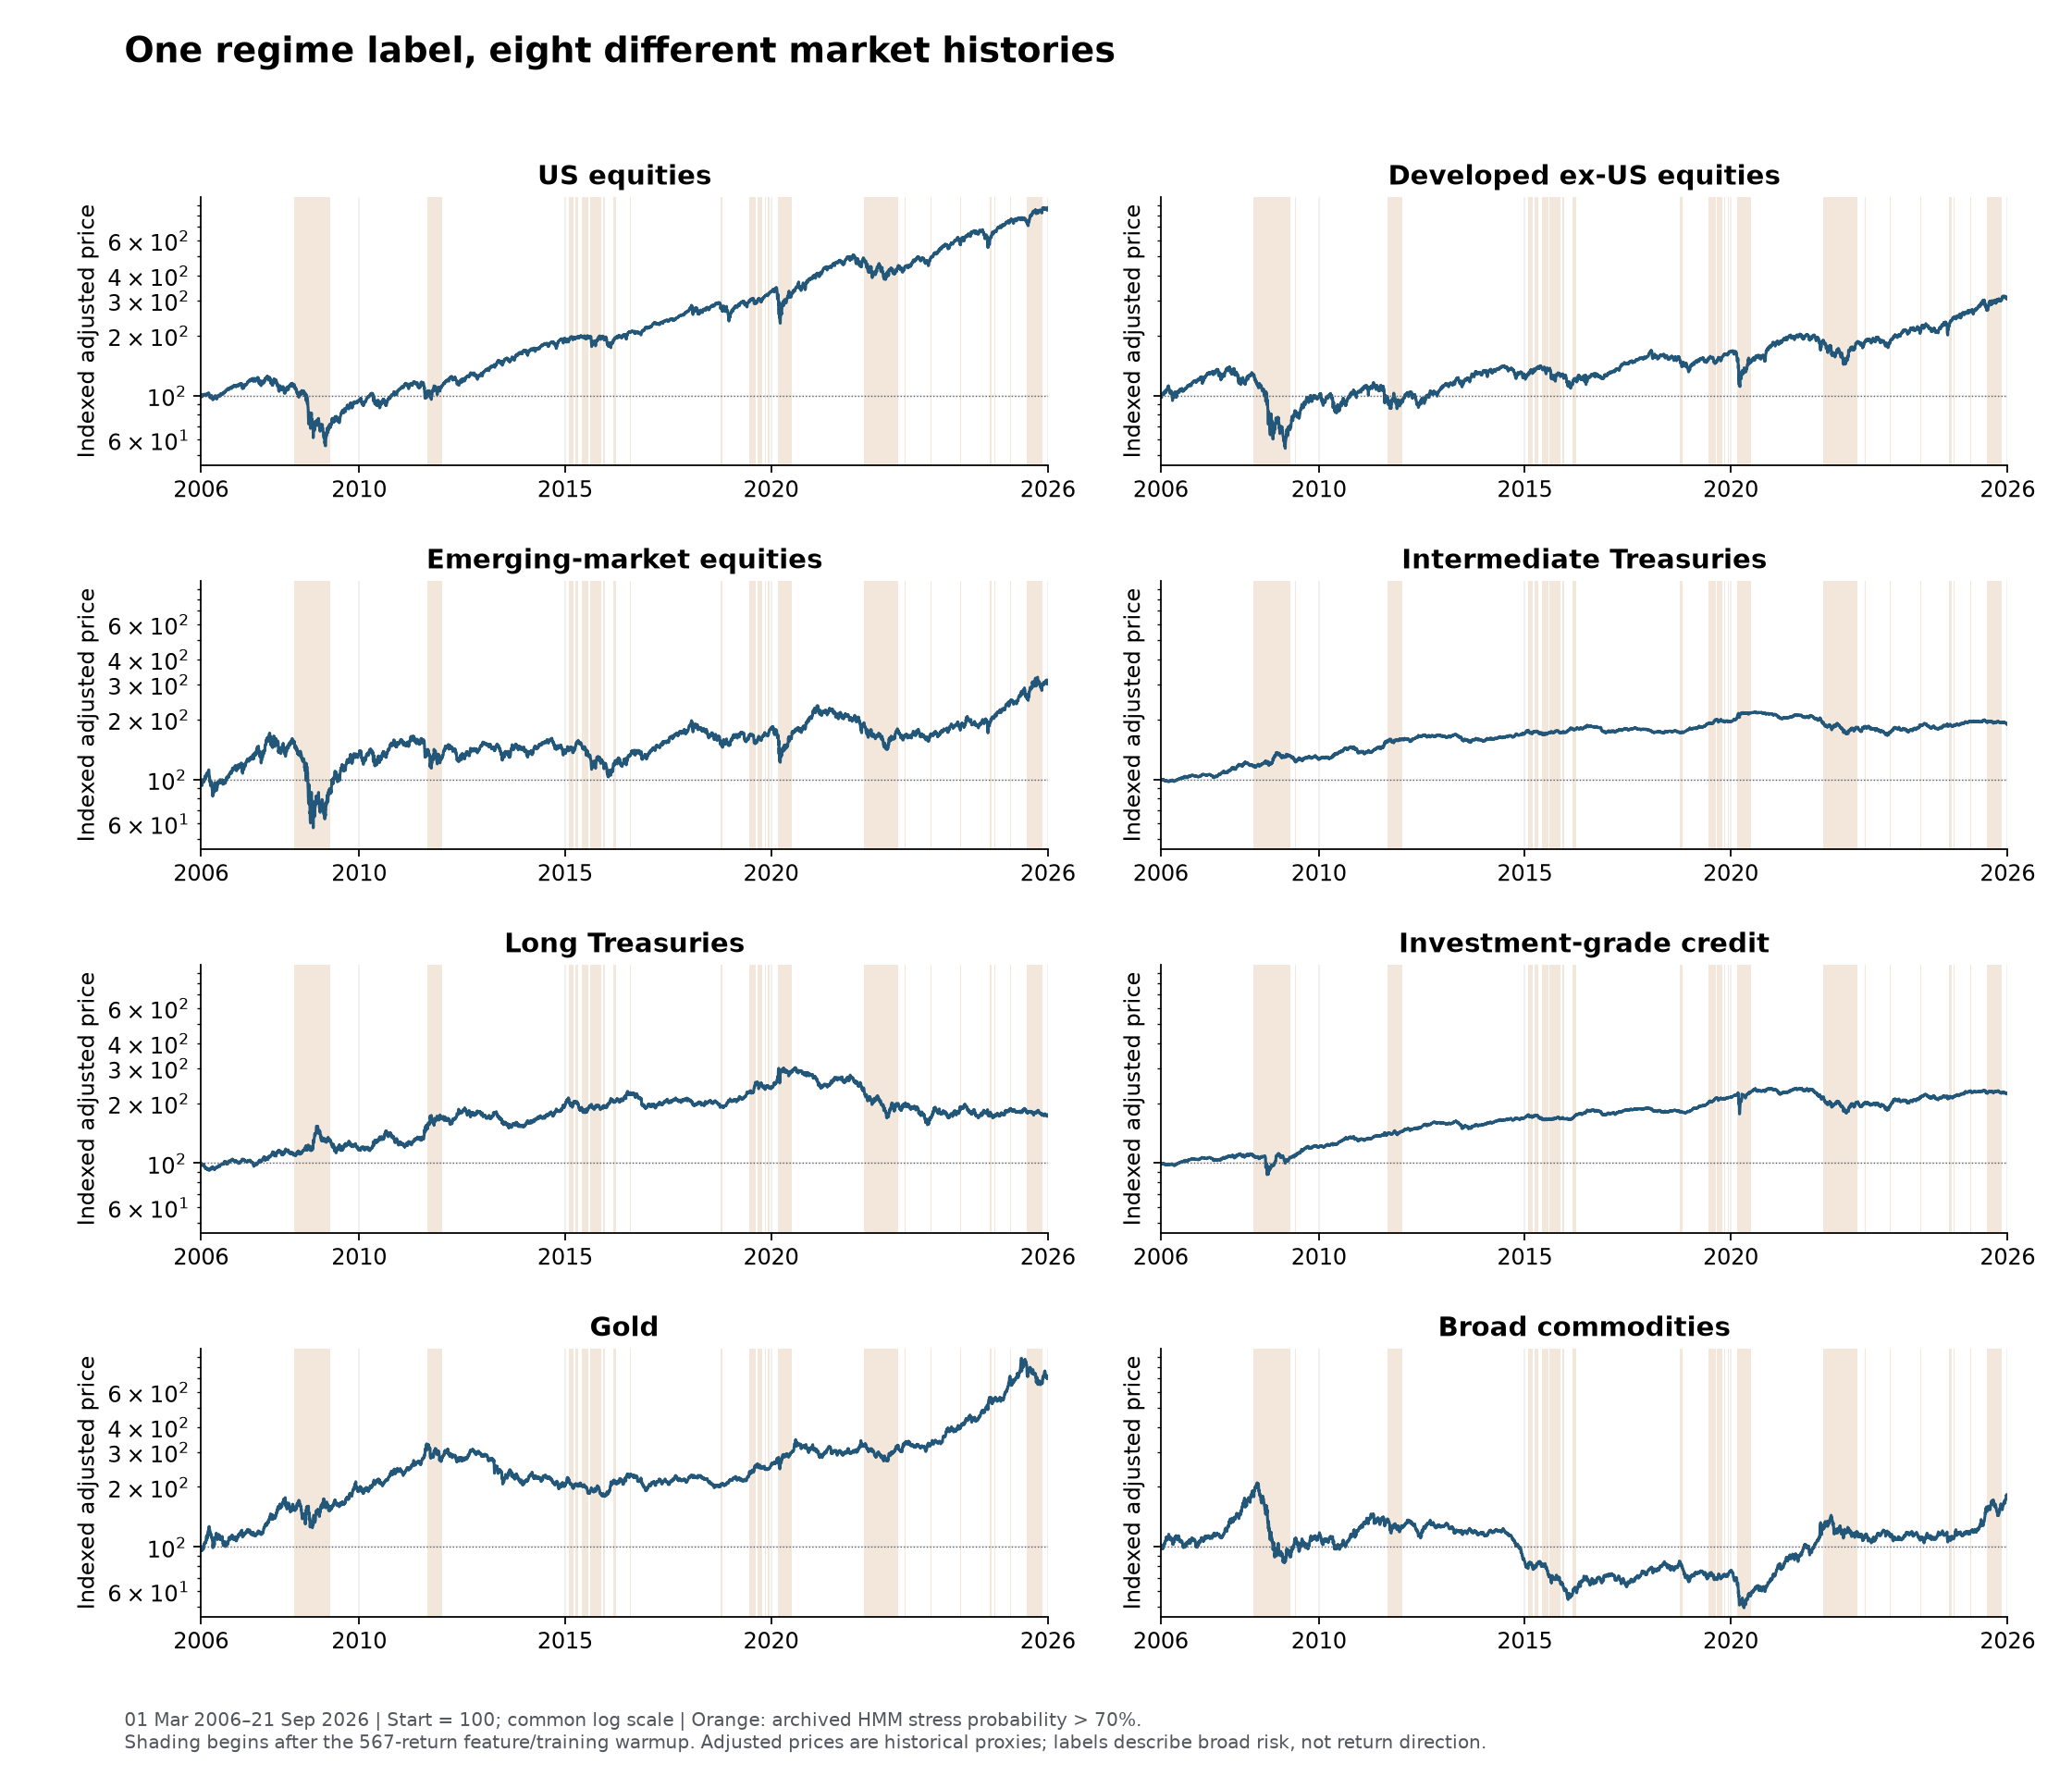

In [4]:
display(Image(filename=str(FIGURES / "market_atlas.png")))

The same broad risk state leaves assets with different return paths. The atlas uses a common log scale, with each exposure indexed to 100. Orange marks archived high-stress probability, not a strategy position.

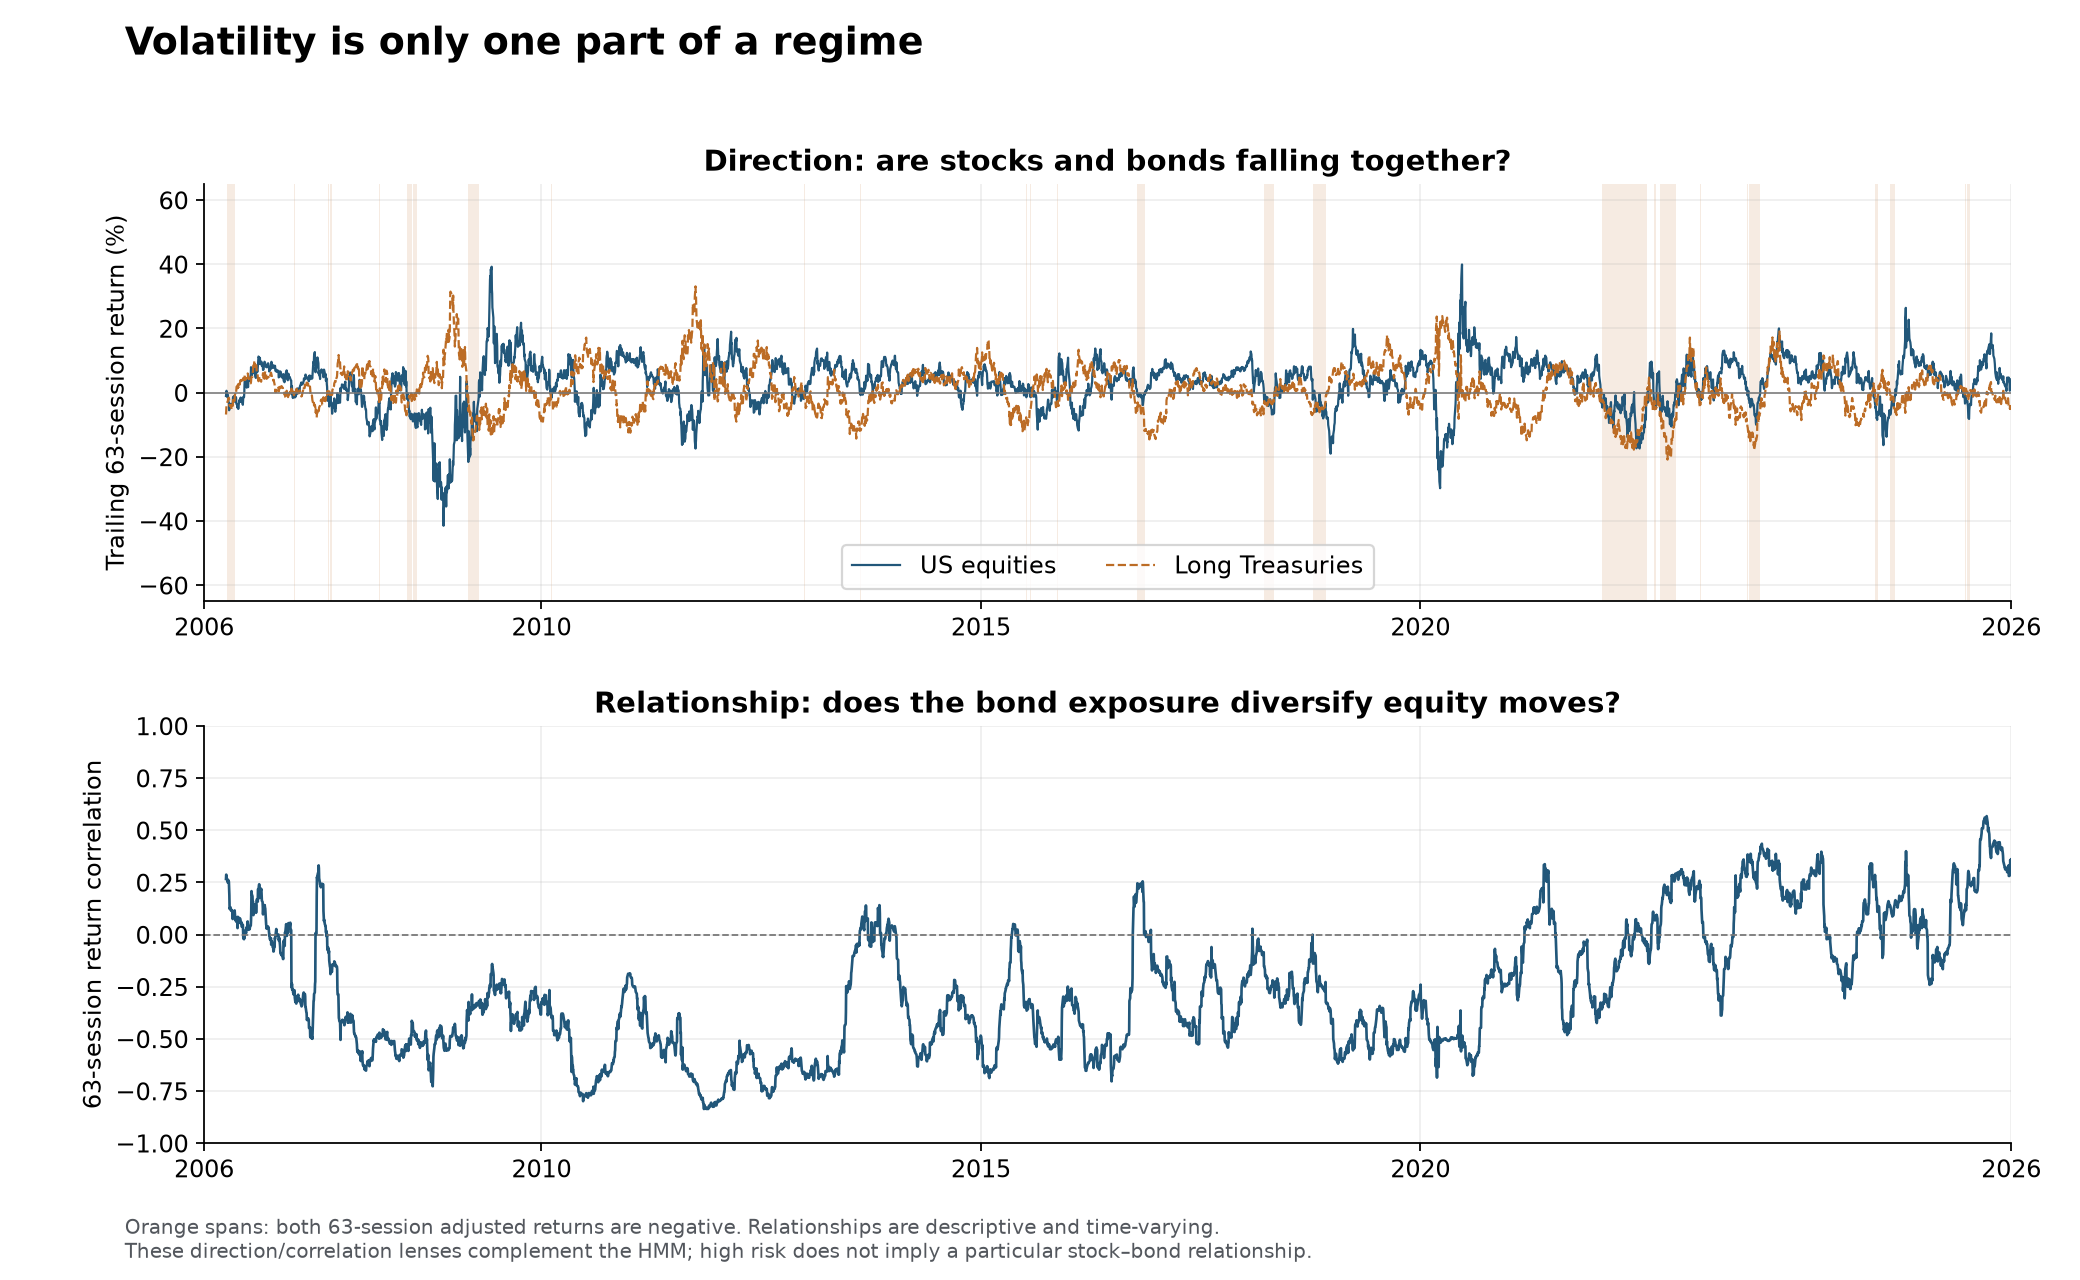

In [5]:
display(Image(filename=str(FIGURES / "market_context.png")))

Quarterly direction and equity–bond dependence supply context that a volatility label alone cannot. The covariance or hedge assumption can need review even when the current marginal-risk state is familiar.

### 2. Choose a representation that matches the research question

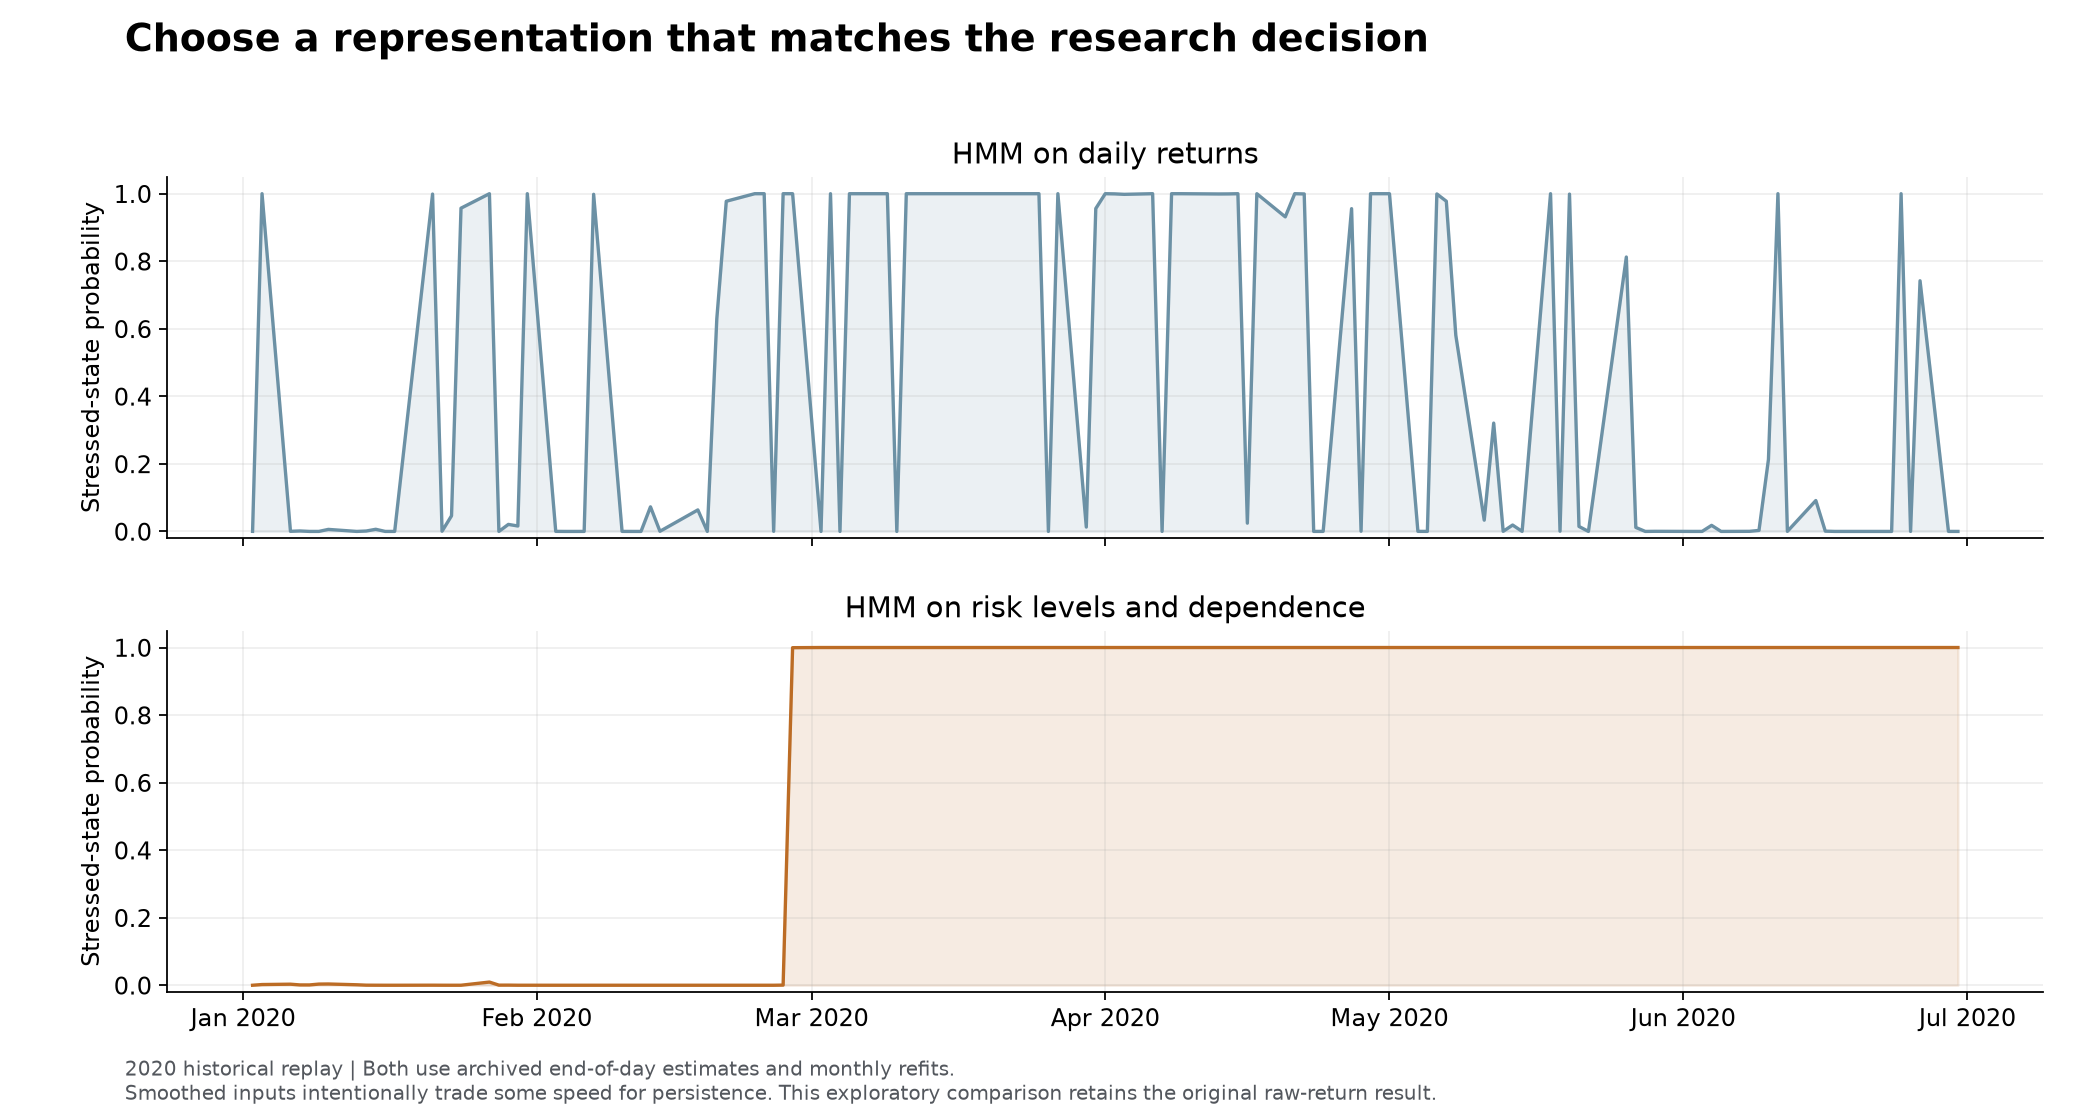

,representation,label_switch_fraction,alarms,alarms_per_year,stressed_probability_share
0,Daily returns,0.5526,78,4.2684,0.1702
1,Risk and dependence features,0.0317,26,1.4228,0.2341


In [6]:
display(Image(filename=str(FIGURES / "representation_comparison.png")))
display(pd.read_csv(RESULTS / "representation_comparison.csv").round(4))

The daily-return model's frequent switching motivated a feature-based description. EWMA risk inputs deliberately add persistence and some delay; the full posterior is model-implied rather than a calibrated probability of an objectively true economic regime. The label-stability comparison is descriptive; the following risk backtest tests the action taken from it.

### 3. Replay what the researcher could see

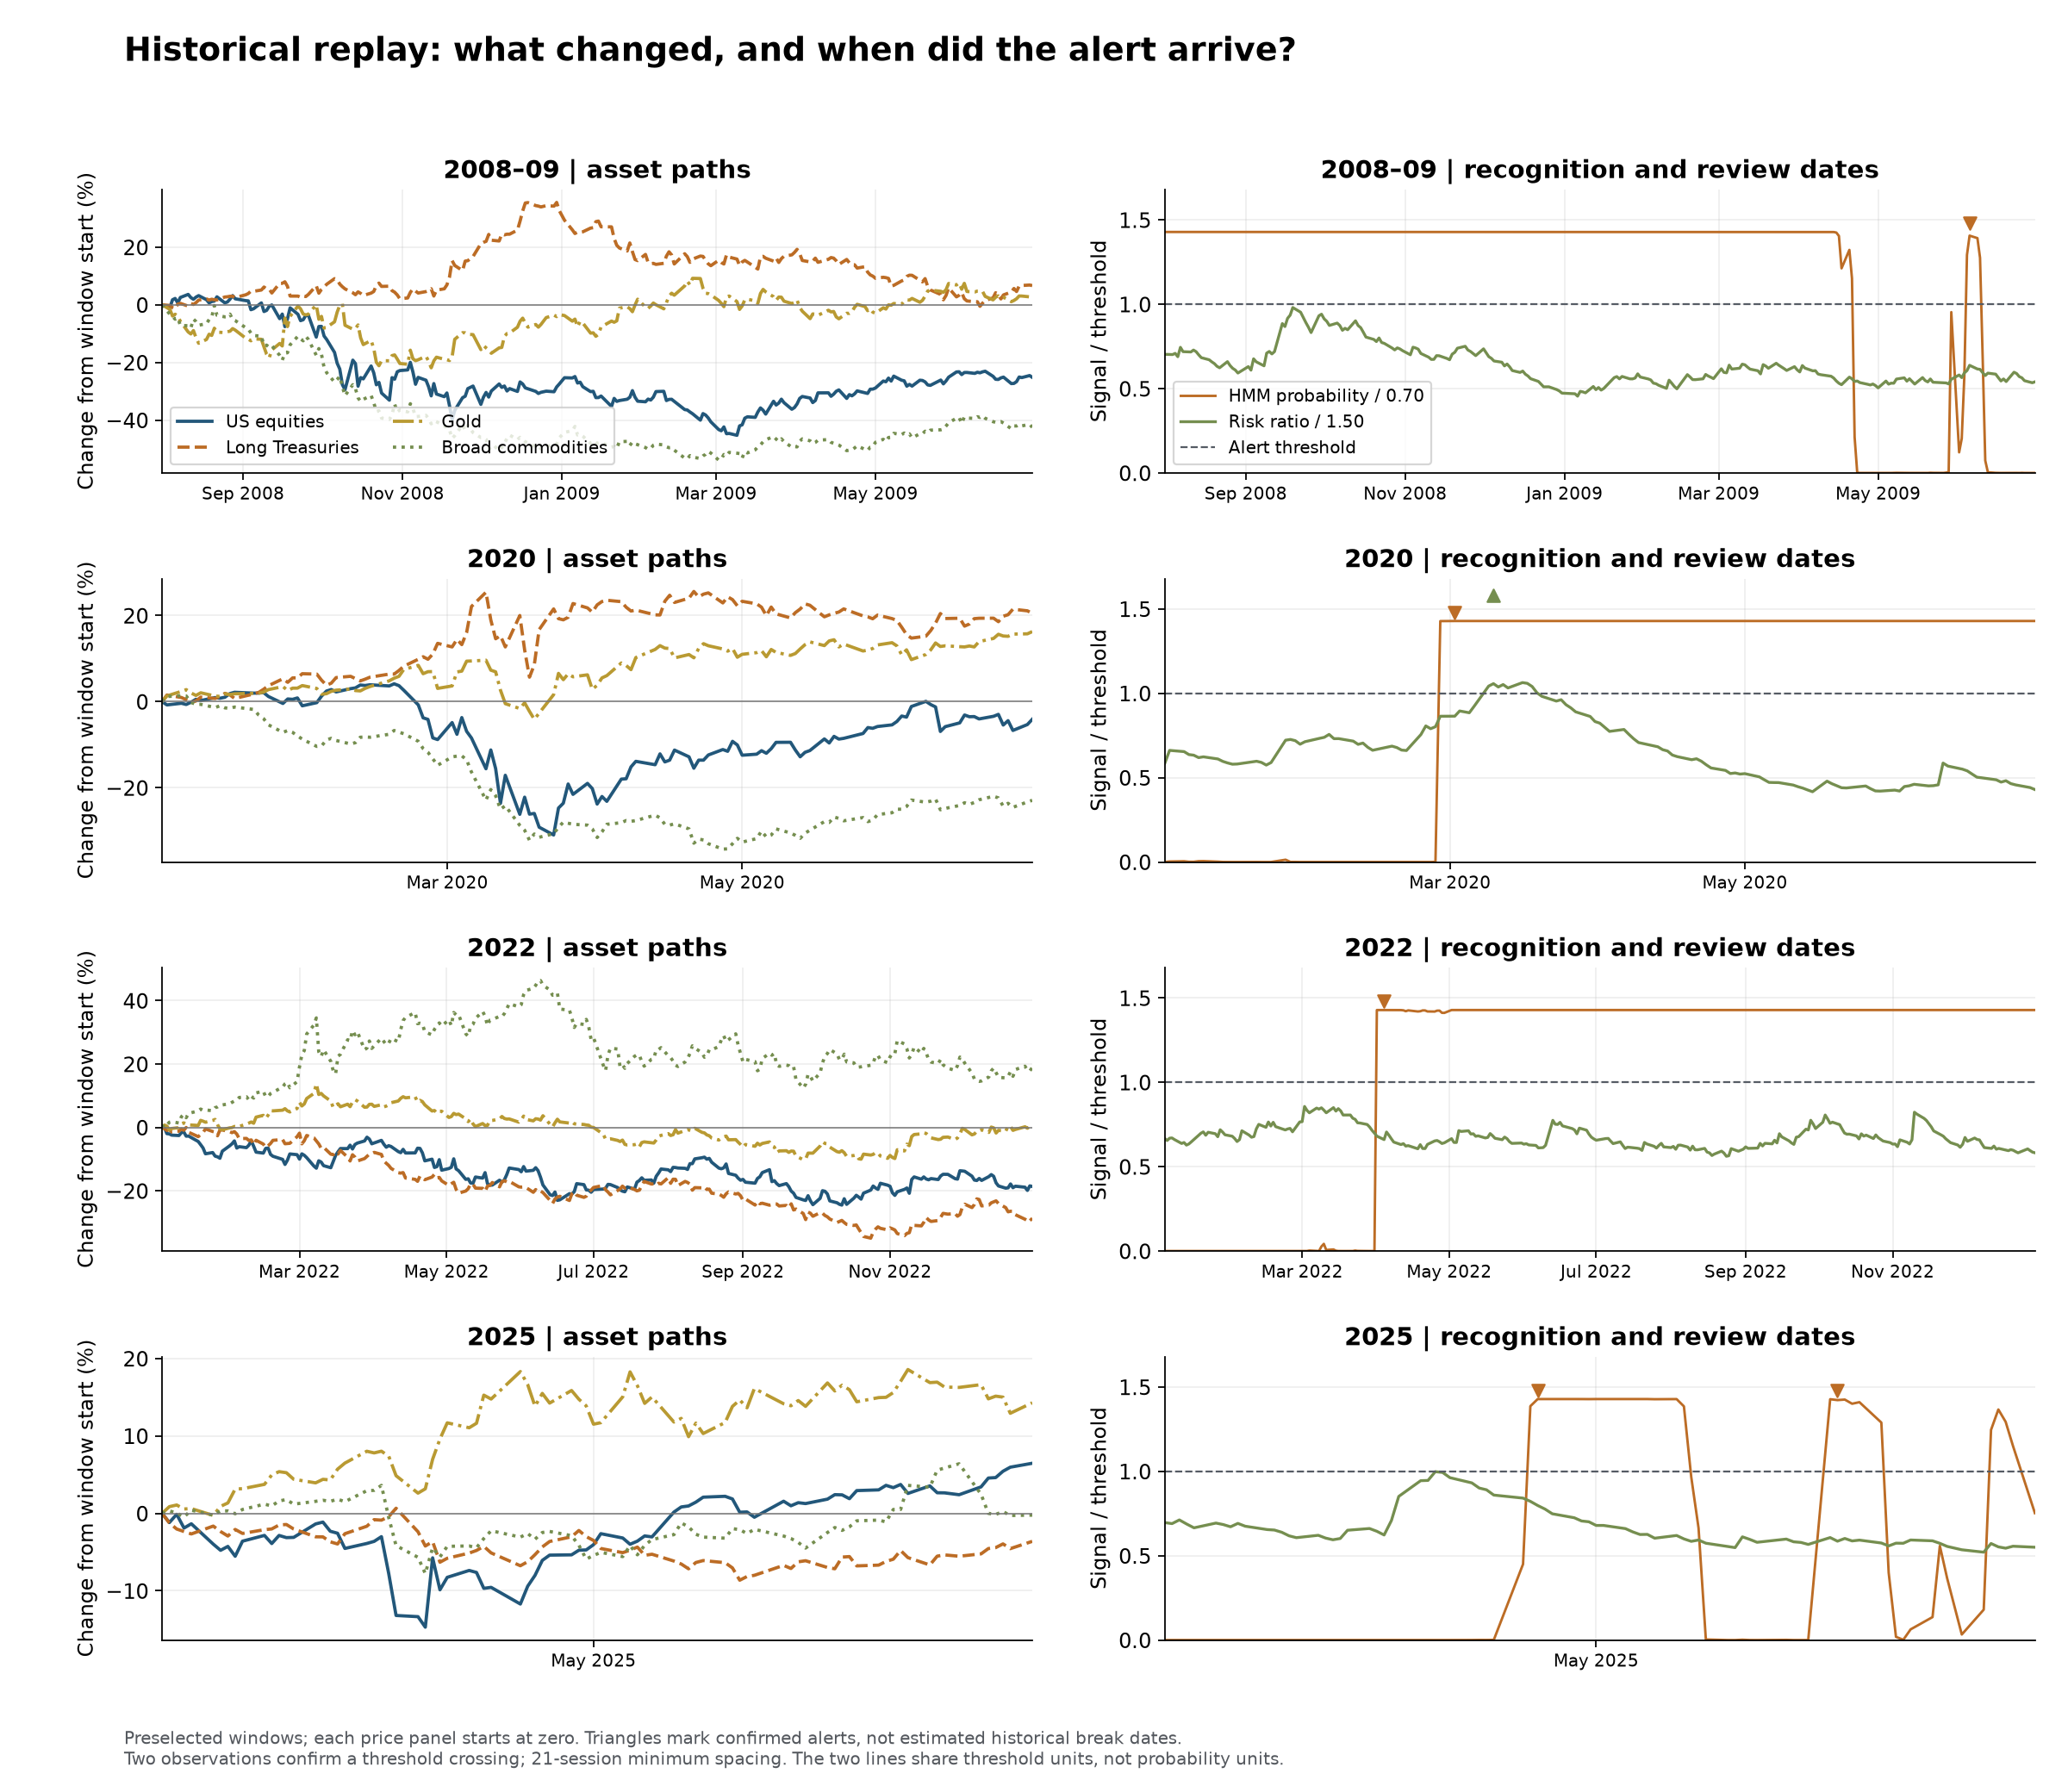

In [7]:
display(Image(filename=str(FIGURES / "episode_replays.png")))

Each triangle is a confirmed review date. The price panels show why a clean retrospective break is different from a timely operational response. Windows were chosen as historical illustrations before evaluation; they are not an independent test set.

In [8]:
events = pd.read_csv(RESULTS / "episode_timing.csv")
display(events.query('method == "HMM reset"').rename(columns={"lag_sessions": "Lag vs observable reference (sessions)"}))

,reference_date,method,alarm_date,Lag vs observable reference (sessions),hmm_stress_at_reference,sessions_since_latest_alarm
11,2008-09-18,HMM reset,NaN,NaN,True,75.0
12,2010-05-21,HMM reset,NaN,NaN,False,242.0
13,2011-08-08,HMM reset,2011-08-02,-4.0,False,4.0
14,2013-06-21,HMM reset,NaN,NaN,False,451.0
15,2014-12-24,HMM reset,2015-02-03,26.0,False,832.0
16,2019-08-22,HMM reset,2019-09-04,8.0,True,44.0
17,2020-03-09,HMM reset,2020-03-02,-5.0,True,5.0
18,2021-03-19,HMM reset,NaN,NaN,False,265.0
19,2022-03-03,HMM reset,2022-04-04,22.0,False,506.0
20,2025-04-10,HMM reset,2025-04-23,8.0,False,170.0


### 4. Make the recalibration rule explicit

In [9]:
# Independent illustration at the first HMM review: a 20-session reset.
signals = pd.read_csv(ROOT / "research/results/paths/practical/signals.csv", index_col="date", parse_dates=True)
review_date = signals.index[signals["HMM reset"]][0]
recent = returns.loc[:review_date].tail(20).to_numpy()
second_moment = recent.T @ recent / len(recent)
forecast_matrix = 0.9 * second_moment + 0.1 * np.diag(np.diag(second_moment))
display(Markdown(f"First HMM review: **{review_date.date()}**"))
display(pd.Series(np.sqrt(252 * np.diag(forecast_matrix)), index=ASSETS.values(), name="Reset annualized risk").map(lambda x: f"{x:.1%}"))

First HMM review: **2008-06-03**

US equities                 13.6%
Developed ex-US equities    14.5%
Emerging-market equities    20.6%
Intermediate Treasuries      7.4%
Long Treasuries             10.4%
Investment-grade credit      7.6%
Gold                        22.3%
Broad commodities           24.3%
Name: Reset annualized risk, dtype: object

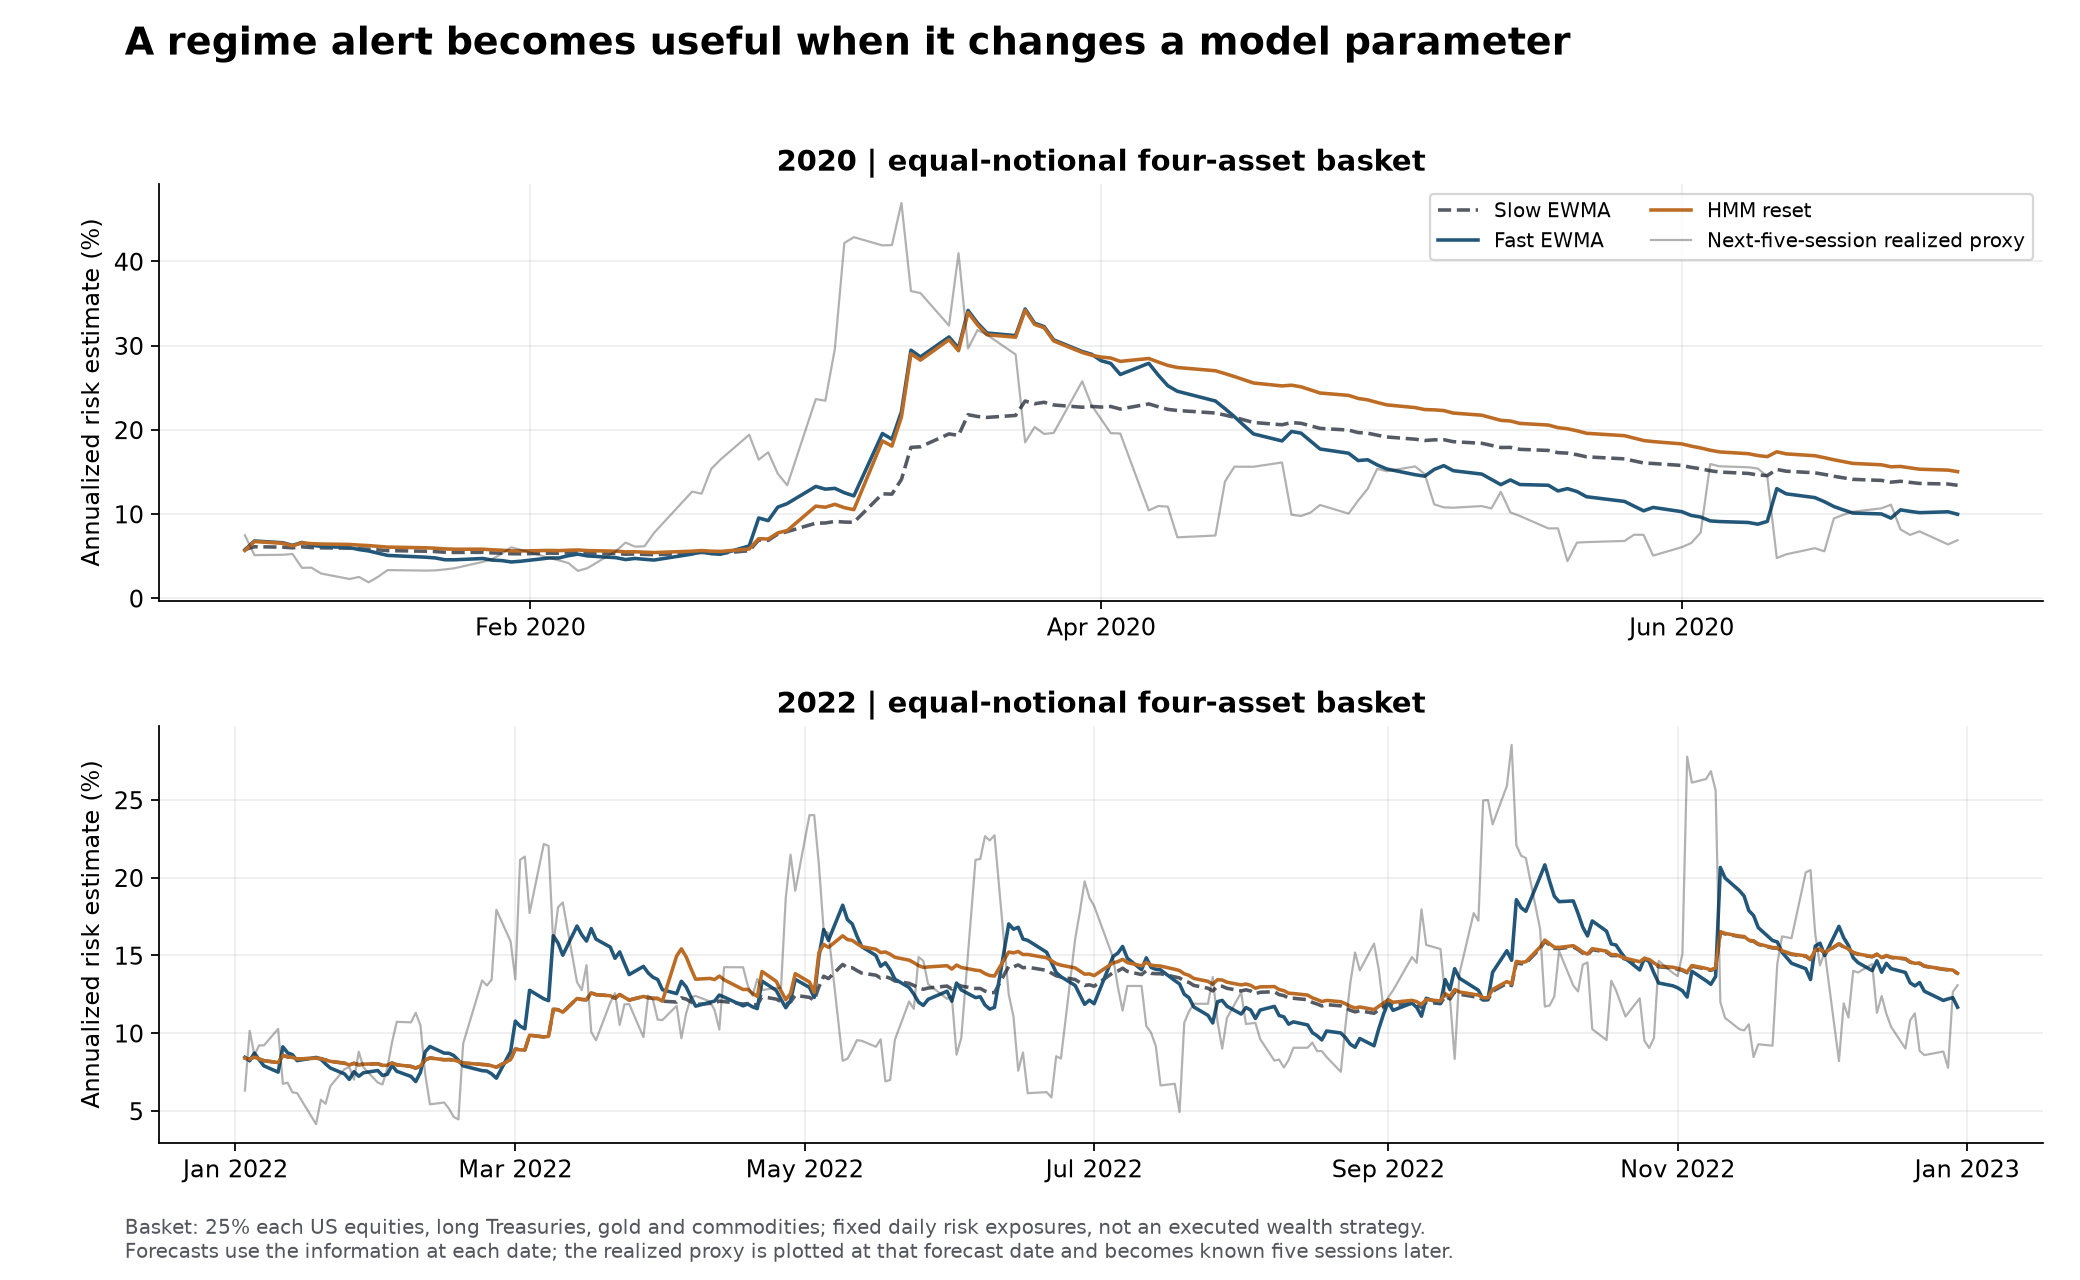

In [10]:
display(Image(filename=str(FIGURES / "calibration_replay.png")))

The realized next-five-session proxy is plotted at its forecast date, but becomes available later. The four-asset basket is a fixed research exposure; the chart is not a net trading backtest.

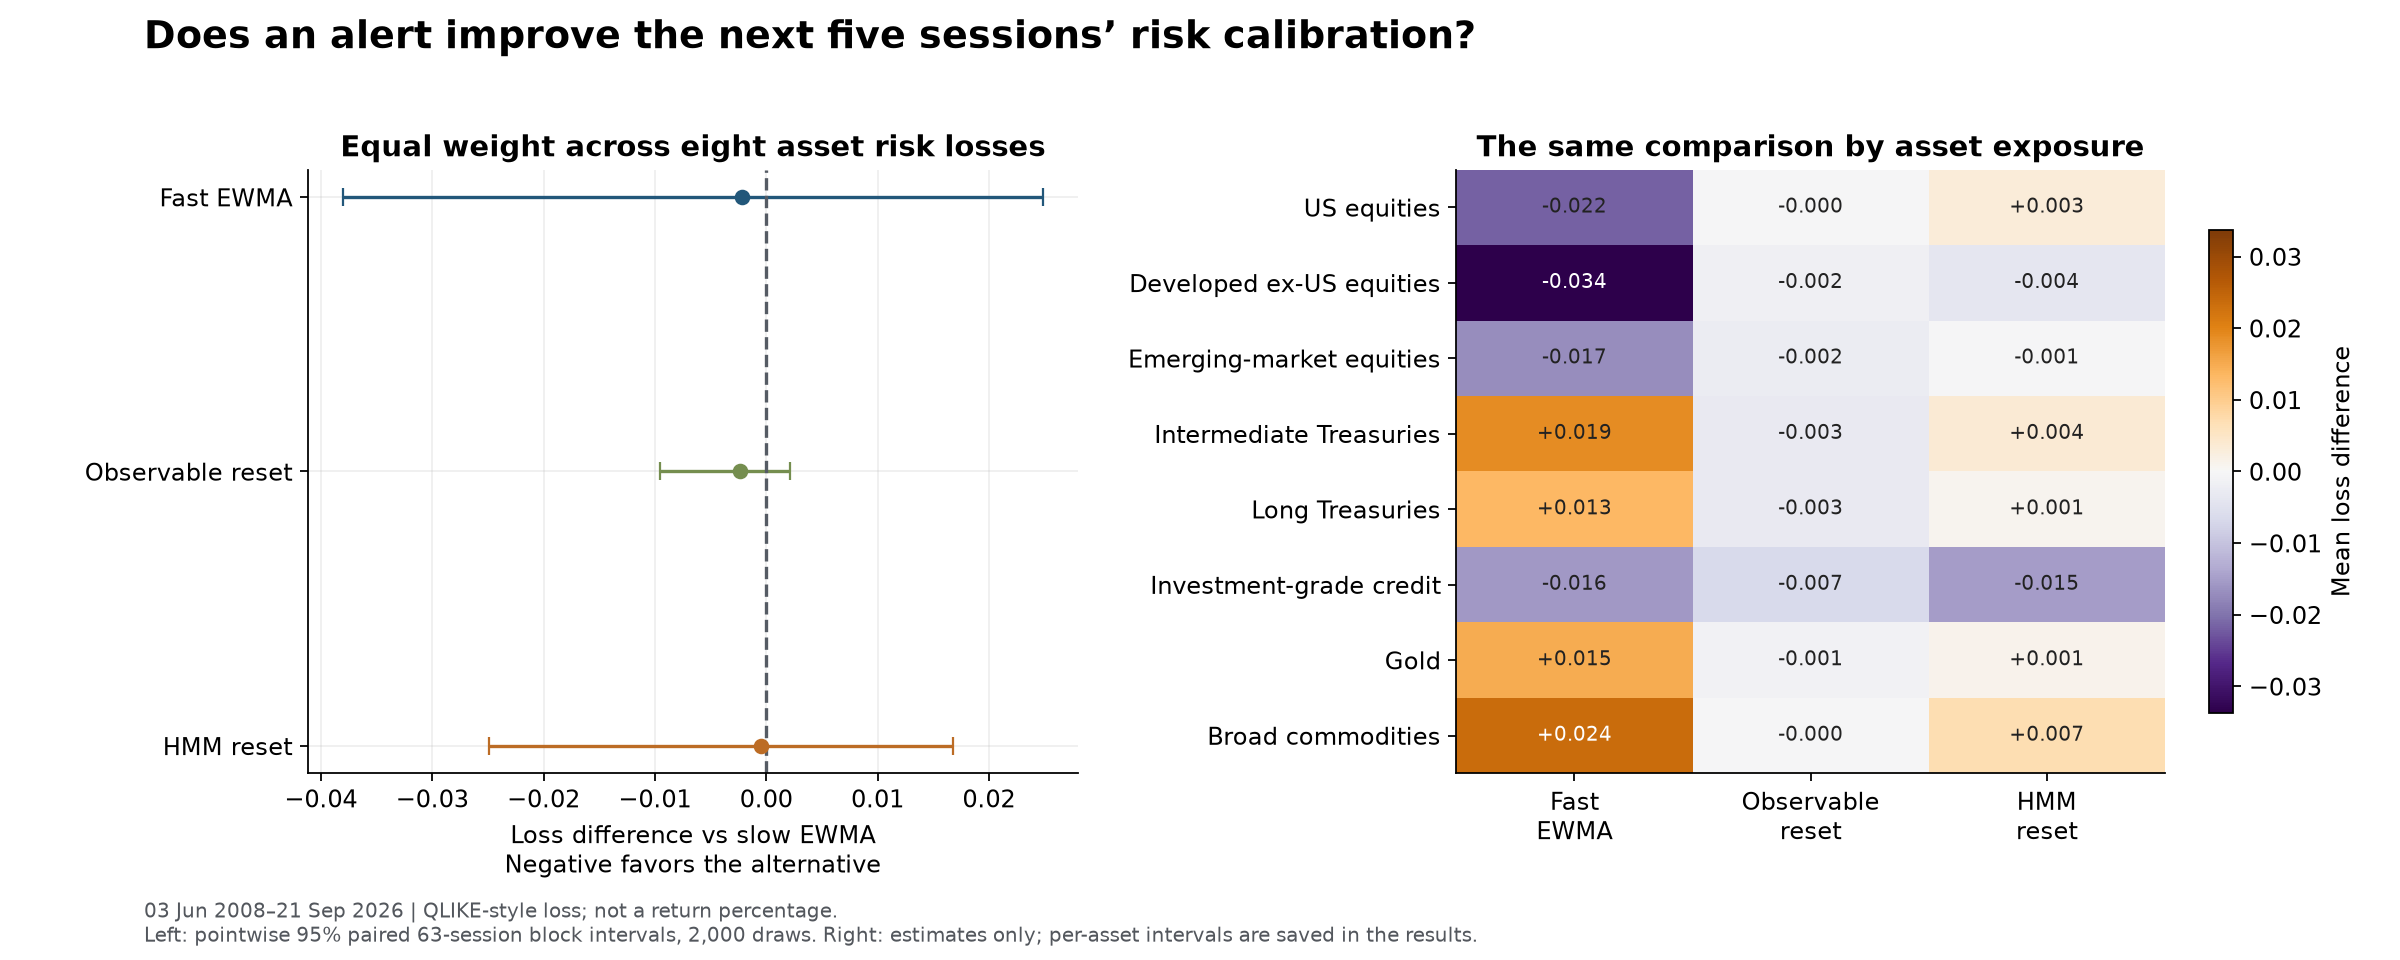

In [11]:
display(Image(filename=str(FIGURES / "calibration_comparison.png")))

In [12]:
display(pd.read_csv(RESULTS / "subperiods.csv").query('method != "HMM state forecast"').pivot(index="period", columns="method", values="mean_loss_difference").round(4))
display(pd.read_csv(RESULTS / "sensitivity.csv")[["variant", "estimate", "lower95", "upper95", "alarms"]].round(4))

method,Fast EWMA,HMM reset,Observable reset,Raw-return HMM reset
period,,,,
2008–2014,-0.0061,-0.0029,0.0000,-0.0138
2015–2019,0.0402,0.0228,0.0000,0.0224
2020–2023,-0.0645,-0.0247,-0.0107,-0.0658
2024–latest,0.0211,-0.0019,0.0000,-0.0028


,variant,estimate,lower95,upper95,alarms
0,Two states,0.0032,-0.0221,0.0207,NaN
1,Seed 41,-0.0002,-0.0246,0.0166,NaN
2,Observable 1.3,-0.0091,-0.0298,0.0051,6.0
3,Observable 1.7,0.0000,0.0000,0.0000,0.0
4,HMM 0.60,-0.0005,-0.0249,0.0167,26.0
5,HMM 0.80,-0.0009,-0.0256,0.0162,27.0


Subperiod, state-count and threshold results show how dependent the decision is on the chosen model. All alternatives remain visible; none silently replaces the declared rule.

### 5. Count the reviews and missed changes

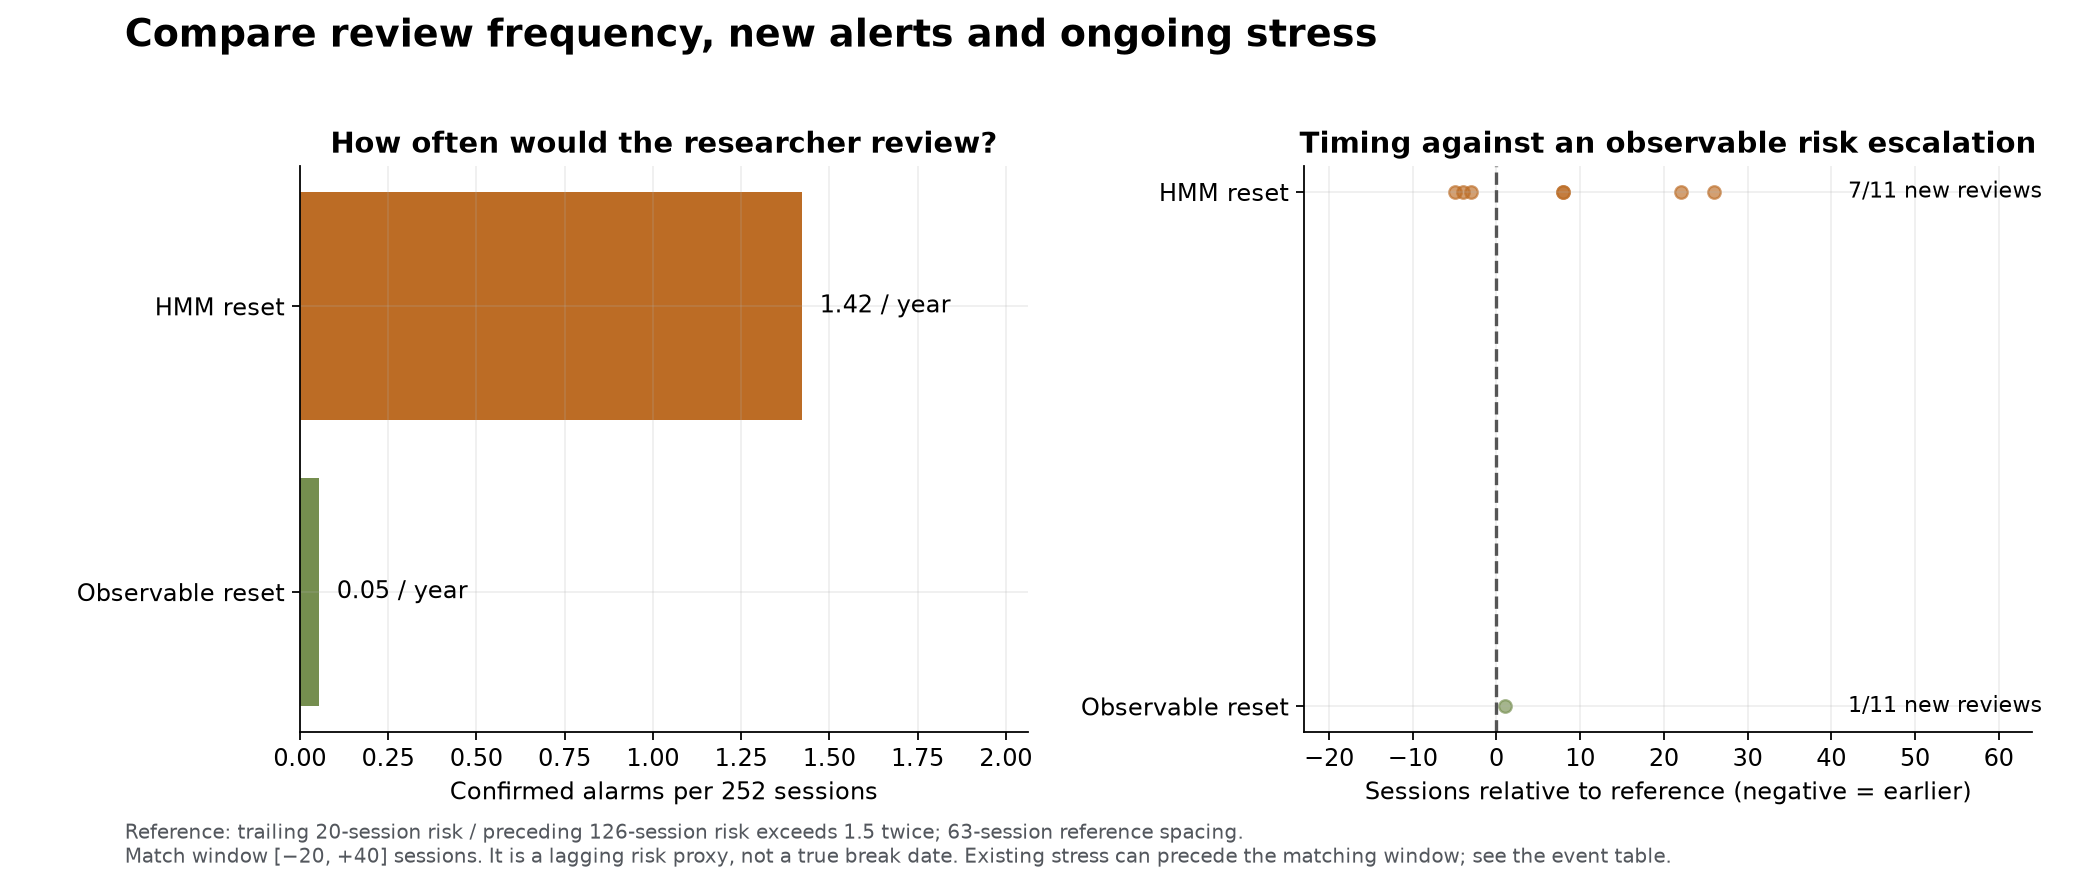

,method,sessions,alarms,alarms_per_year,reference_episodes,matched_episodes,unmatched_alarms,fast_mode_fraction
0,Observable reset,4605,1,0.055,11,1,0,0.005
1,HMM reset,4605,26,1.423,11,7,19,0.124


In [13]:
display(Image(filename=str(FIGURES / "alert_timing.png")))
display(pd.read_csv(RESULTS / "review_burden.csv").round(3))

In [14]:
display(pd.read_csv(RESULTS / "synthetic_summary.csv").round(3))

,case,threshold,paths,prechange_alarm_rate,any_alarm_rate,hit_by_60,conditional_median_delay
0,Stationary,1.3,100,0.0,0.00,0.00,NaN
1,Stationary,1.5,100,0.0,0.00,0.00,NaN
2,Stationary,1.7,100,0.0,0.00,0.00,NaN
3,Abrupt volatility,1.3,100,0.0,0.36,0.36,8.0
4,Abrupt volatility,1.5,100,0.0,0.00,0.00,NaN
5,Abrupt volatility,1.7,100,0.0,0.00,0.00,NaN
6,Gradual volatility,1.3,100,0.0,0.00,0.00,NaN
7,Gradual volatility,1.5,100,0.0,0.00,0.00,NaN
8,Gradual volatility,1.7,100,0.0,0.00,0.00,NaN
9,Correlation only,1.3,100,0.0,0.03,0.00,NaN


The conservative observable threshold produces one historical alert and misses the stipulated synthetic volatility changes. Zero null alarms alone is therefore uninformative. The already declared looser/tighter threshold checks expose this tradeoff. Synthetic detection probabilities are not historical true-break accuracy.

### 6. Use delayed labels deliberately

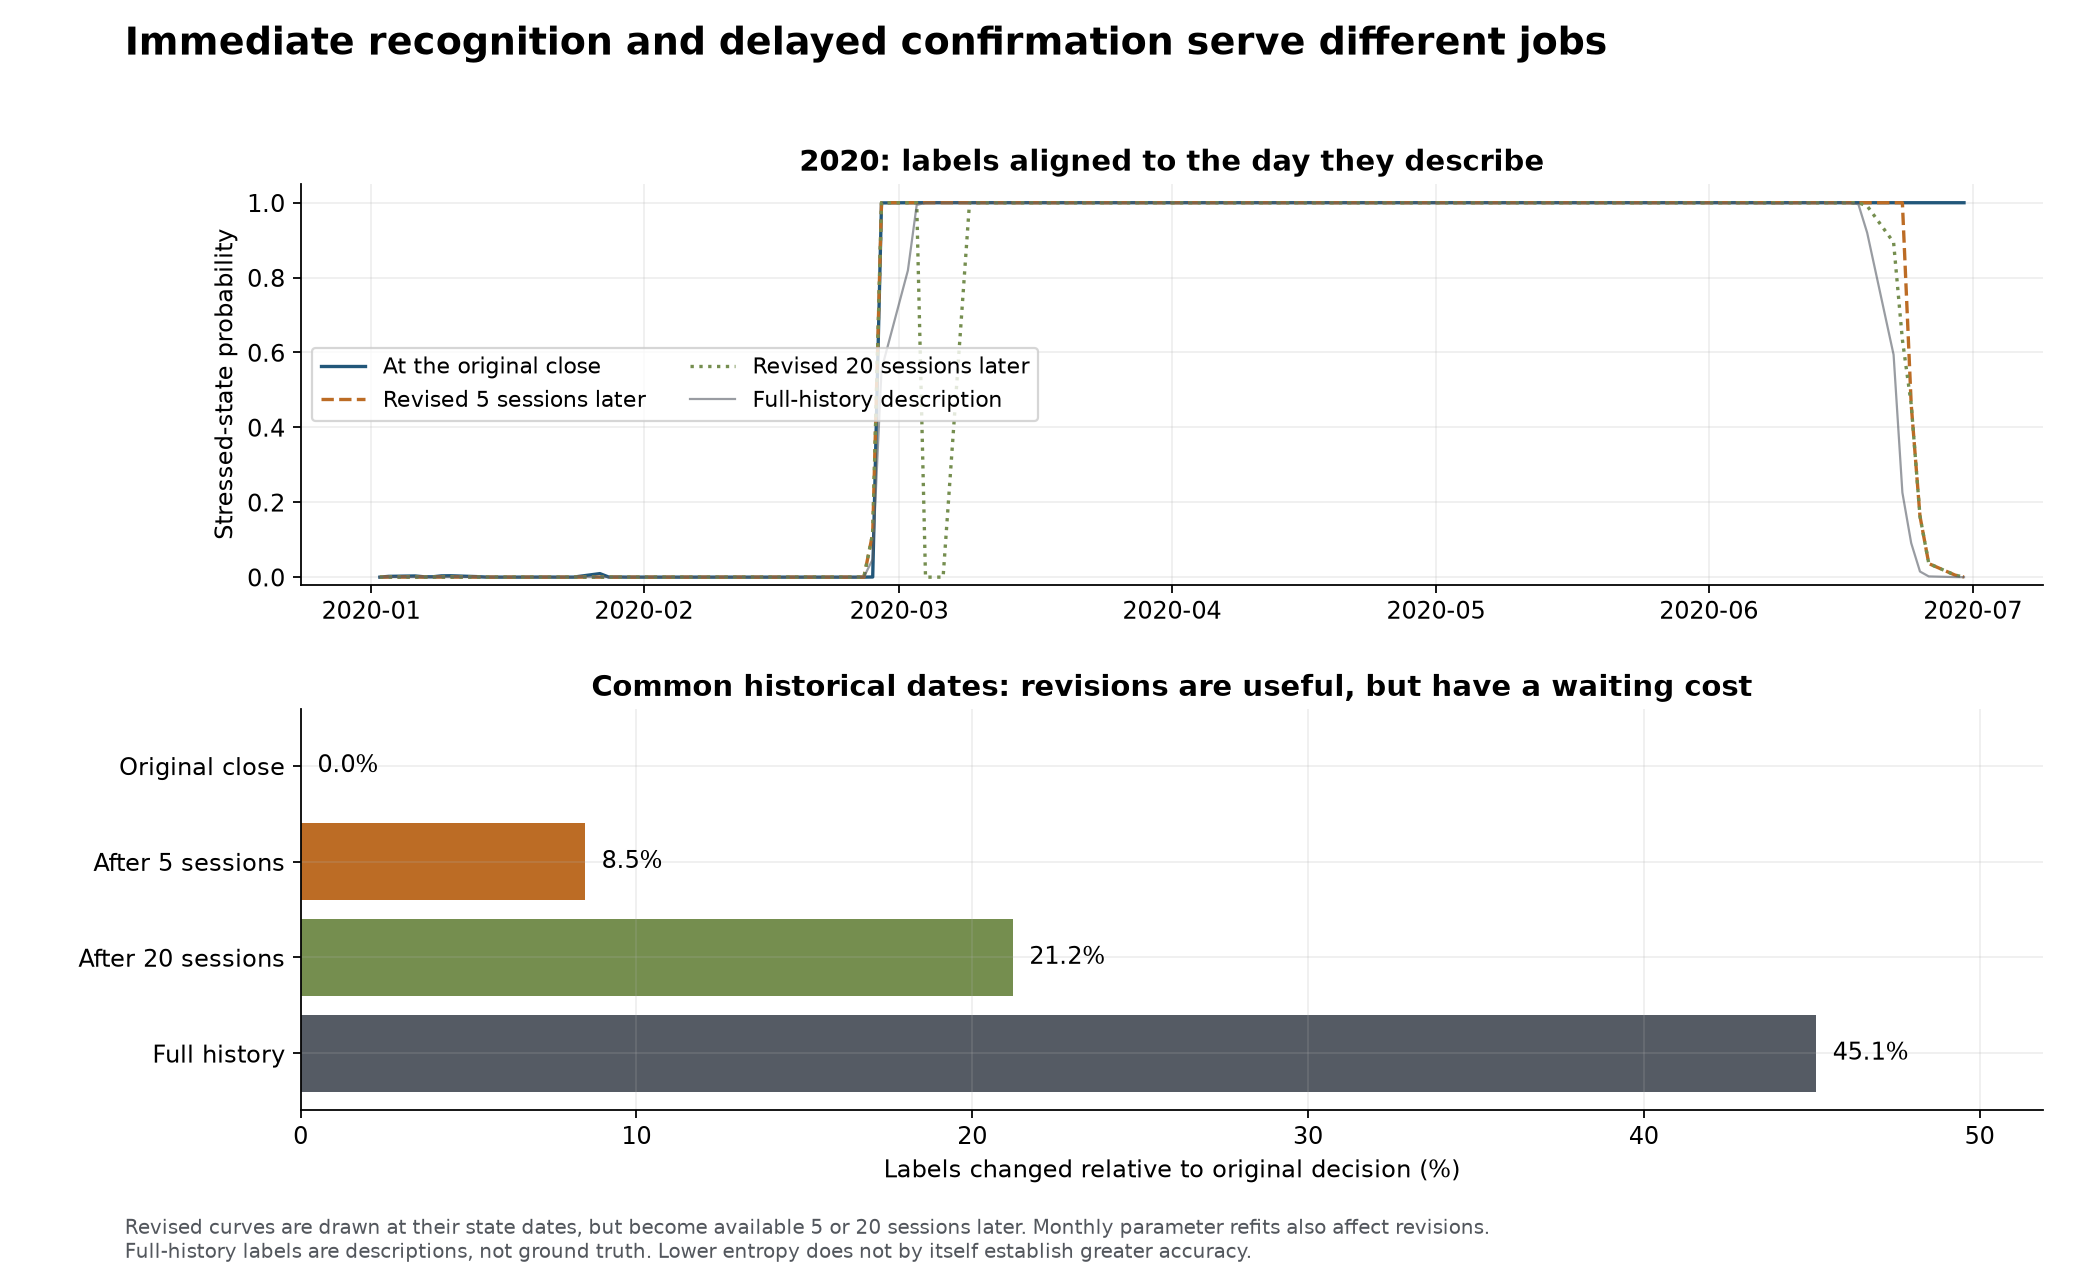

,lens,waiting_sessions,n,changed_from_original,agreement_with_full_description,mean_normalized_entropy
0,original,0.0,4585,0.000,0.549,0.032
1,lag5,5.0,4585,0.085,0.555,0.026
2,lag20,20.0,4585,0.212,0.548,0.020
3,full,NaN,4585,0.451,1.000,0.043


In [15]:
display(Image(filename=str(FIGURES / "revision_tradeoff.png")))
display(pd.read_csv(RESULTS / "label_revisions.csv").round(3))

The table quantifies how many labels change after five sessions, twenty sessions and full-history re-estimation. Revisions include parameter refits. Agreement with the final description is not accuracy against ground truth, and a concentrated posterior need not be well calibrated.

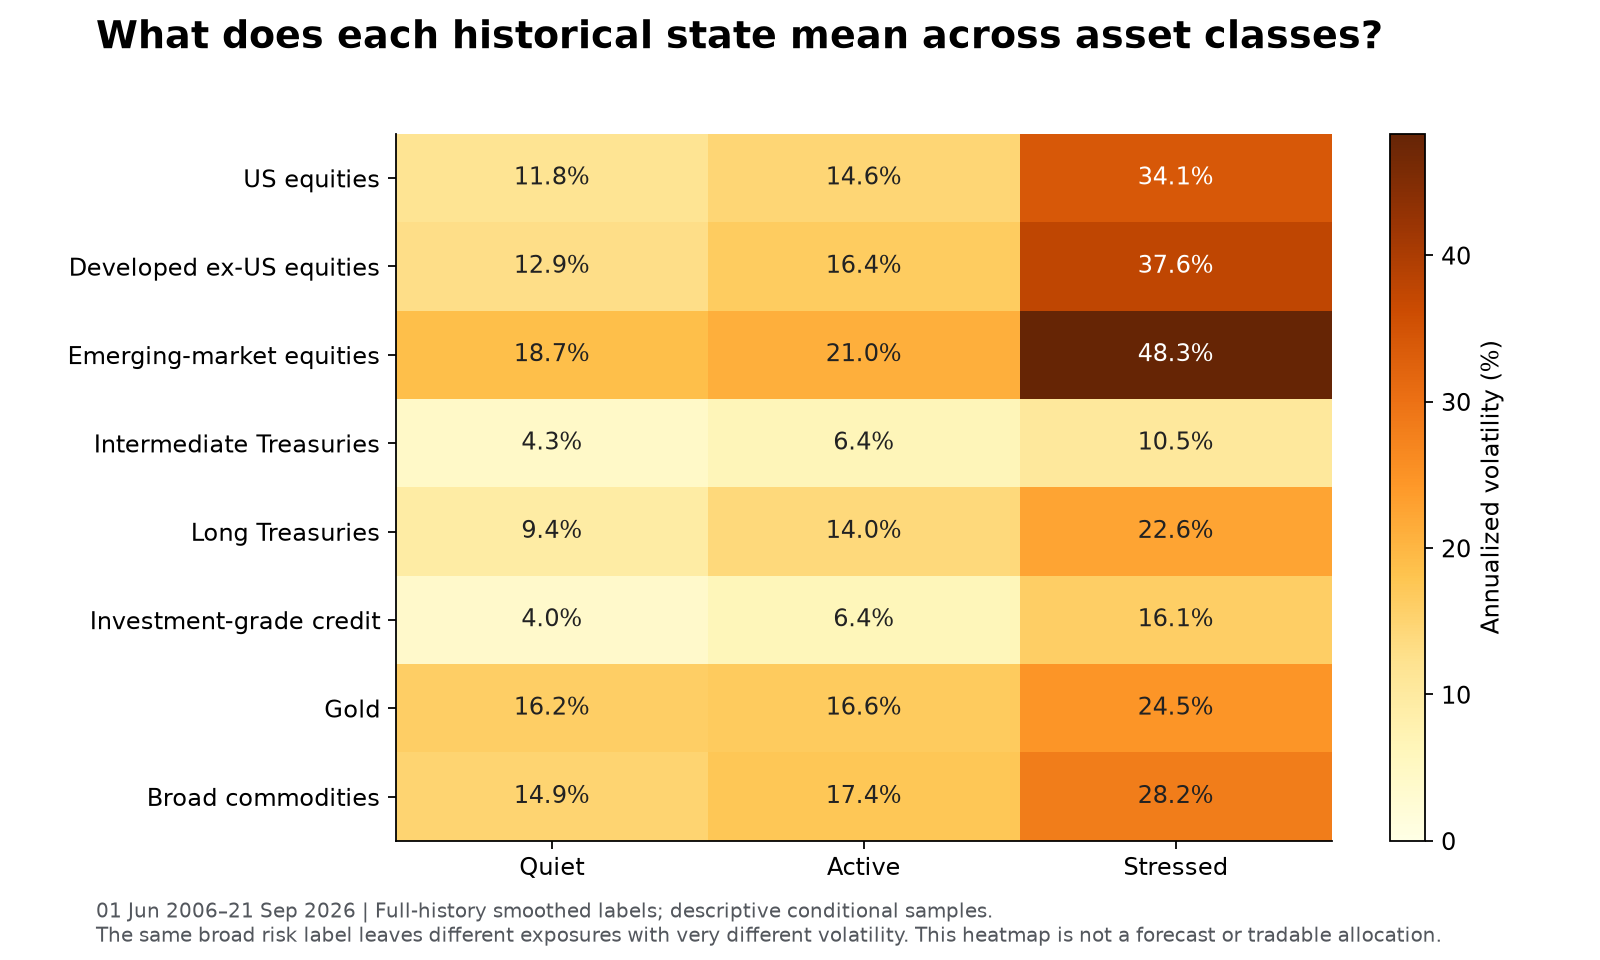

In [16]:
display(Image(filename=str(FIGURES / "state_fingerprints.png")))

These conditional historical volatilities help characterize episodes. They are estimated after labeling the complete history and cannot establish future conditional returns.

### 7. A dated research snapshot

In [17]:
snapshot = json.loads((RESULTS / "latest_monitor.json").read_text())
display(Markdown(f"As of **{snapshot['as_of']}**: **{snapshot['state']}** state. Equity–bond 63-session correlation: **{snapshot['equity_bond_correlation_63']:+.2f}**."))
display(pd.Series(snapshot["state_probabilities"], name="Model-implied probability"))
display(pd.Series(snapshot["asset_return_63_sessions"], name="63-session adjusted return").map(lambda x: f"{x:+.1%}"))

As of **2026-09-21**: **Active** state. Equity–bond 63-session correlation: **+0.36**.

Quiet       0.000003
Active      0.999986
Stressed    0.000011
Name: Model-implied probability, dtype: float64

US equities                  +4.2%
Developed ex-US equities     +1.5%
Emerging-market equities     -3.3%
Intermediate Treasuries      -2.0%
Long Treasuries              -3.9%
Investment-grade credit      -2.2%
Gold                         +3.6%
Broad commodities           +18.9%
Name: 63-session adjusted return, dtype: object

## Takeaways

Use immediate recognition to schedule a review, a delayed map to refine an event study, and full-history states to organize scenarios. Tie the review to a specific parameter change and compare its subsequent performance with a simpler continuous update. Judge the reset on subsequent calibration and review burden, and the descriptive model on its usefulness for investigating market structure. The almost silent volatility gate illustrates why low alert frequency alone is not successful detection.

[Researcher’s playbook](docs/04-calibration-playbook.md) explains the workflow. [Next experiments](research/RESEARCH_AGENDA.md) distinguish completed work from unrun correlation detectors, state-weighted calibration and alpha-model adaptations.

## Calculation appendix

Reconstruct every scored target from the price-derived returns, reconcile matrices and reset dates, and verify source/code/output hashes.

In [18]:
from research.check_artifacts import independent_checks
independent_checks()

Independent target, timing, risk-matrix, reset, headline and provenance checks passed.


[Sources](research/SOURCES.md) · [Full evidence](docs/02-results.md) · [Reproduction](docs/05-reproduction.md) · [Publication boundary](PUBLICATION.md).